# Preprocessing of station current data

Note: Something is off with directions after 2019-01-01 for Flinten7 station. They have been removed for now. 

In [1]:
import pandas as pd
import numpy as np

In [2]:
def convert_to_u_v(speed, direction):
    # Convert direction from CW (North = 0°) to CCW (East = 0°)
    direction_ccw_deg = (90 - direction) % 360
    direction_rad = np.deg2rad(direction_ccw_deg)

    # Calculate u- and v-components
    u = speed * np.cos(direction_rad)
    v = speed * np.sin(direction_rad)

    # Alternative calculation which achieves the same by swapping sin and cos
    #u = speed * np.sin(np.deg2rad(direction))
    #v = speed * np.cos(np.deg2rad(direction))
    return u,v

def uv_to_speed_direction(u, v):
    # Calculate speed and direction from u- and v-components
    speed = np.sqrt(u**2 + v**2)
    direction_deg = np.rad2deg(np.arctan2(v, u))
    direction_ccw_deg = (90 - direction_deg) % 360
    return speed, direction_ccw_deg

def calculate_depth_averaged_velocities(data): 
    # Set values to nan if they are exactly 0:
    data = data.copy()
    data.loc[data["Current direction"] == 0,"Current direction"] = np.nan
    data.loc[data["Current speed"] == 0,"Current speed"] = np.nan

    data['u'],data['v'] = convert_to_u_v(data['Current speed'],data['Current direction'])
    for idx in data.index.unique():
        # Loop over indices and calculate depth averaged velocities. 
        # Also convert to m/s
        data.loc[idx,'u_depth_averaged'] = data.loc[idx,'u'].mean()/100
        data.loc[idx,'v_depth_averaged'] = data.loc[idx,'v'].mean()/100
    # Round data
    data = data.round({'u_depth_averaged': 4, 'v_depth_averaged': 4})
    return data

def calculate_velocities(data): 
    data = data.copy()
    # Set values to nan if they are exactly 0:
    data.loc[data["Current direction"] == 0,"Current direction"] = np.nan
    data.loc[data["Current speed"] == 0,"Current speed"] = np.nan

    data['u'],data['v'] = convert_to_u_v(data['Current speed'],data['Current direction'])
    data['u'] = data['u']/100
    data['v'] = data['v']/100

    # Round data
    data = data.round({'u': 4, 'v': 4})
    return data

In [3]:
swedish_to_english = { 'Strömriktning':"Current direction", 'Kvalitet':"Quality_d",'Mätdjup (m)':"Measuring depth (m)_d",
                            'Strömhastighet':"Current speed", 'Kvalitet.1':"Quality_s",'Mätdjup (m).1':"Measuring depth (m)_s"}

## Flinten7 station

In [4]:
Flinten7 = pd.read_csv("raw_data/smhi-opendata_2_3_35137_20260520_111930.csv",index_col=0,sep=";", parse_dates=True)
Flinten7.rename(columns = swedish_to_english,inplace=True)
Flinten7.index.names = ['datetime_UTC']

# Filter data after time steps and quality flags.
Flinten7 = Flinten7.loc[(Flinten7.index >= "2023-01-01") & (Flinten7.index < "2026-01-01") & (Flinten7["Quality_d"] == "G") & (Flinten7["Quality_s"] == "G") ].drop(columns=["Quality_d","Quality_s","Unnamed: 7","Tidsutsnitt"])
Flinten7


,Current direction,Measuring depth (m)_d,Current speed,Measuring depth (m)_s
datetime_UTC,,,,
2023-01-01 00:00:00,263.16,0,26.75,0
2023-01-01 00:00:00,182.94,2,4.12,2
2023-01-01 00:00:00,149.20,4,33.44,4
2023-01-01 00:00:00,245.41,6,1.54,6
2023-01-01 01:00:00,268.25,0,28.81,0
...,...,...,...,...
2025-12-31 22:00:00,39.38,6,7.20,6
2025-12-31 23:00:00,29.30,0,37.04,0
2025-12-31 23:00:00,28.94,2,21.60,2


In [5]:
import matplotlib.pyplot as plt

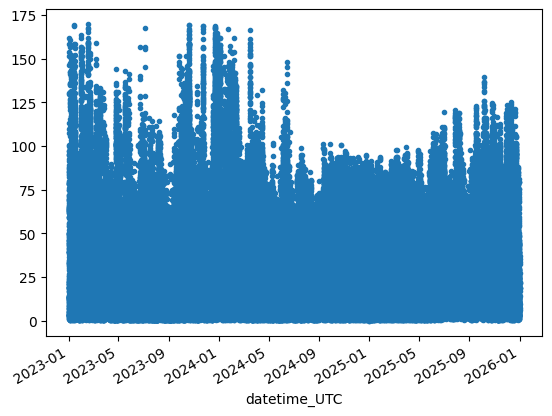

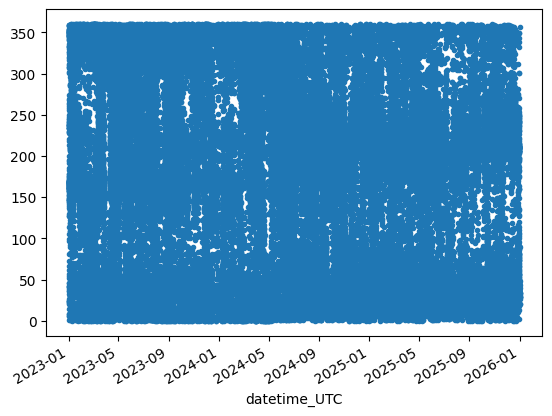

In [6]:
Flinten7["Current speed"].plot(style='.')
plt.show()
Flinten7["Current direction"].plot(style='.')
plt.show()

### Depth averaged

In [7]:
# Convert Current speed and directions to u and v components and calculate depth averaged velocities
Flinten7_depthave = calculate_depth_averaged_velocities(Flinten7).dropna()
Flinten7_depthave


,Current direction,Measuring depth (m)_d,Current speed,Measuring depth (m)_s,u,v,u_depth_averaged,v_depth_averaged
datetime_UTC,,,,,,,,
2023-01-01 00:00:00,263.16,0,26.75,0,-26.559610,-3.185849,-0.0276,-0.0917
2023-01-01 00:00:00,182.94,2,4.12,2,-0.211315,-4.114577,-0.0276,-0.0917
2023-01-01 00:00:00,149.20,4,33.44,4,17.122713,-28.723619,-0.0276,-0.0917
2023-01-01 00:00:00,245.41,6,1.54,6,-1.400335,-0.640828,-0.0276,-0.0917
2023-01-01 01:00:00,268.25,0,28.81,0,-28.796563,-0.879815,-0.0629,-0.1498
...,...,...,...,...,...,...,...,...
2025-12-31 22:00:00,39.38,6,7.20,6,4.568117,5.565277,0.0948,0.1659
2025-12-31 23:00:00,29.30,0,37.04,0,18.126726,32.301446,0.1172,0.1727
2025-12-31 23:00:00,28.94,2,21.60,2,10.452099,18.902741,0.1172,0.1727


In [8]:
Flinten7_depthave.drop_duplicates(subset=["u_depth_averaged","v_depth_averaged"],inplace=True)
Flinten7_depthave

,Current direction,Measuring depth (m)_d,Current speed,Measuring depth (m)_s,u,v,u_depth_averaged,v_depth_averaged
datetime_UTC,,,,,,,,
2023-01-01 00:00:00,263.16,0,26.75,0,-26.559610,-3.185849,-0.0276,-0.0917
2023-01-01 01:00:00,268.25,0,28.81,0,-28.796563,-0.879815,-0.0629,-0.1498
2023-01-01 02:00:00,310.56,0,8.23,0,-6.252540,5.351508,0.0131,-0.1483
2023-01-01 03:00:00,46.46,0,19.03,0,13.794726,13.109021,0.0584,-0.1549
2023-01-01 04:00:00,129.90,0,13.37,0,10.256998,-8.576182,0.0715,-0.2914
...,...,...,...,...,...,...,...,...
2025-12-31 19:00:00,349.29,0,48.87,0,-9.081908,48.018703,0.0344,0.2290
2025-12-31 20:00:00,356.32,0,35.49,0,-2.277889,35.416823,0.0838,0.2197
2025-12-31 21:00:00,20.30,0,33.44,0,11.601528,31.363006,0.0858,0.1743


In [9]:
df = Flinten7_depthave[["u_depth_averaged","v_depth_averaged"]].rename(columns={"u_depth_averaged":"u","v_depth_averaged":"v"})

df.to_csv("../observations/Flinten7_u_v_depth_averaged.csv", date_format='%Y-%m-%dT%H:%M:%S')

### All levels

In [10]:
# Convert Current speed and directions to u and v components and calculate depth averaged velocities
Flinten7_depths = calculate_velocities(Flinten7).dropna()
Flinten7_depths

,Current direction,Measuring depth (m)_d,Current speed,Measuring depth (m)_s,u,v
datetime_UTC,,,,,,
2023-01-01 00:00:00,263.16,0,26.75,0,-0.2656,-0.0319
2023-01-01 00:00:00,182.94,2,4.12,2,-0.0021,-0.0411
2023-01-01 00:00:00,149.20,4,33.44,4,0.1712,-0.2872
2023-01-01 00:00:00,245.41,6,1.54,6,-0.0140,-0.0064
2023-01-01 01:00:00,268.25,0,28.81,0,-0.2880,-0.0088
...,...,...,...,...,...,...
2025-12-31 22:00:00,39.38,6,7.20,6,0.0457,0.0557
2025-12-31 23:00:00,29.30,0,37.04,0,0.1813,0.3230
2025-12-31 23:00:00,28.94,2,21.60,2,0.1045,0.1890


In [11]:
df = Flinten7_depths[["Measuring depth (m)_d","u","v"]].rename(columns={"Measuring depth (m)":"depth"})

df.to_csv("../observations/Flinten7_u_v.csv", date_format='%Y-%m-%dT%H:%M:%S')

## Check other stations as well

In [12]:
# LandskronaHamn
dat = pd.read_csv("raw_data/smhi-opendata_2_3_35242_20260520_111919.csv",index_col=0,sep=";", parse_dates=True)
dat.rename(columns = swedish_to_english,inplace=True)
dat.index.names = ['datetime_UTC']

# Filter data after time steps and quality flags.
dat = dat.loc[(dat.index >= "2023-01-01") & (dat.index < "2026-01-01") & (dat["Quality_d"] == "G") & (dat["Quality_s"] == "G") ].drop(columns=["Quality_d","Quality_s","Unnamed: 7","Tidsutsnitt"])
dat


,Current direction,Measuring depth (m)_d,Current speed,Measuring depth (m)_s
datetime_UTC,,,,
2025-10-01 01:00:00,197.63,4,1.03,4
2025-10-01 02:00:00,218.55,4,1.03,4
2025-10-01 03:00:00,201.44,4,5.14,4
2025-10-01 04:00:00,223.88,4,2.57,4
2025-10-01 05:00:00,36.16,4,0.90,4
...,...,...,...,...
2025-12-31 19:00:00,11.97,4,5.14,4
2025-12-31 20:00:00,0.05,4,3.60,4
2025-12-31 21:00:00,352.40,4,6.69,4


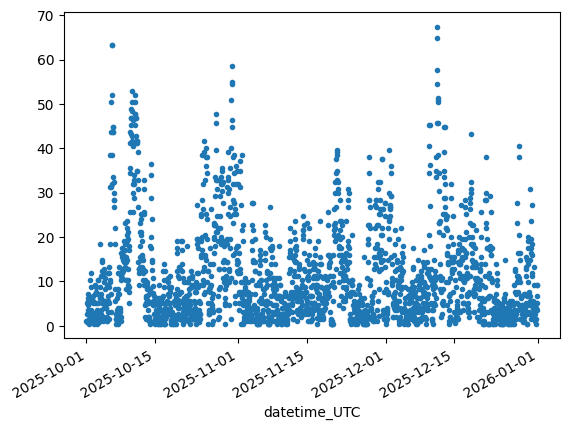

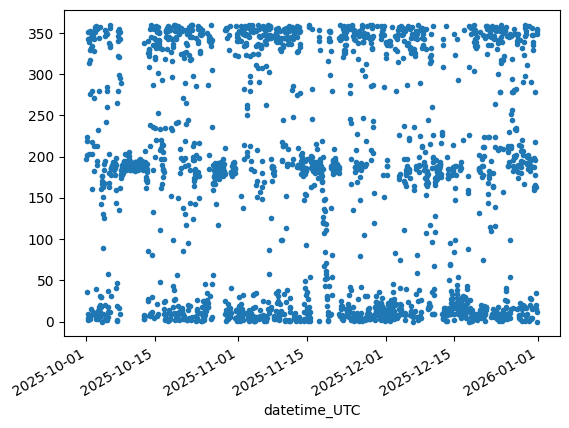

In [13]:
dat["Current speed"].plot(style='.')
plt.show()
dat["Current direction"].plot(style='.')
plt.show()

## Other two stations

In [14]:
dirs = ["smhi-opendata_2_3_35136_20260520_111943.csv","smhi-opendata_2_3_35242_20260520_111919.csv"]
stations = ["Flinten16", "LandskronaHamn"]

for i,d in enumerate(dirs):
    data = pd.read_csv(f"raw_data/{d}",index_col=0,sep=";", parse_dates=True)
    data.rename(columns = swedish_to_english,inplace=True)
    data.index.names = ['datetime_UTC']

    # Filter data after time steps and quality flags.
    data = data.loc[(data.index >= "2023-01-01") & (data.index<"2026-01-01") & (data["Quality_d"] == "G") & (data["Quality_s"] == "G") ].drop(columns=["Quality_d","Quality_s","Unnamed: 7","Tidsutsnitt"])
    
    # Convert Current speed and directions to u and v components and calculate depth averaged velocities
    data_da = calculate_depth_averaged_velocities(data)
    data_da.drop_duplicates(subset=["u_depth_averaged","v_depth_averaged"],inplace=True)
    data_da[["u_depth_averaged","v_depth_averaged"]].rename(columns={"u_depth_averaged":"u","v_depth_averaged":"v"}).to_csv(f"../observations/{stations[i]}_u_v_depth_averaged.csv", date_format='%Y-%m-%dT%H:%M:%S')

    # Also save just the u and v at different depths
    data_depths = calculate_velocities(data).dropna()
    data_depths[["Measuring depth (m)_d","u","v"]].rename(columns={"Measuring depth (m)_d":"depth"}).to_csv(f"../observations/{stations[i]}_u_v.csv", date_format='%Y-%m-%dT%H:%M:%S')
